In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

# Veri setini okuma (Dosyayı sola yüklediğin için doğrudan adını yazabilirsin)
df = pd.read_csv('wfp_ukraine.csv')

# İlk 5 satırı göster
display(df.head())

# Temel bilgiler ve eksik veriler
print("Veri Boyutu:", df.shape)
print("\nEksik Veri Sayıları:")
print(df.isnull().sum())

# Temel istatistikler
display(df.describe())

,country_code,date,county,subcounty,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,price_flag,price_type,currency,local_price,price_usd
0,UKR,2026-01-15,Cherkaska,Cherkaska,Cherkasy,1858.0,49.44,32.06,cereals and tubers,Barley,307.0,KG,actual,Retail,UAH,21.49,0.49
1,UKR,2026-01-15,Cherkaska,Cherkaska,Cherkasy,1858.0,49.44,32.06,cereals and tubers,Bread (first grade flour),460.0,KG,actual,Retail,UAH,44.14,1.01
2,UKR,2026-01-15,Cherkaska,Cherkaska,Cherkasy,1858.0,49.44,32.06,cereals and tubers,Bread (high grade flour),459.0,KG,actual,Retail,UAH,57.48,1.32
3,UKR,2026-01-15,Cherkaska,Cherkaska,Cherkasy,1858.0,49.44,32.06,cereals and tubers,Bread (rye),374.0,KG,actual,Retail,UAH,40.77,0.94
4,UKR,2026-01-15,Cherkaska,Cherkaska,Cherkasy,1858.0,49.44,32.06,cereals and tubers,Buckwheat,669.0,KG,actual,Retail,UAH,44.95,1.03


Veri Boyutu: (6770, 17)

Eksik Veri Sayıları:
country_code       0
date            1634
county          1634
subcounty       1634
market          1634
market_id       1634
latitude        1634
longitude       1634
category        1634
commodity       1634
commodity_id    1634
unit            1634
price_flag      1634
price_type      1634
currency        1634
local_price     1634
price_usd       1634
dtype: int64


,market_id,latitude,longitude,commodity_id,local_price,price_usd
count,5136.000000,5136.000000,5136.000000,5136.000000,5136.000000,5136.000000
mean,1871.051402,49.252290,29.815156,441.255452,59.250625,1.343172
std,7.817719,1.336097,3.980713,309.115133,57.378494,1.302075
min,1858.000000,46.480000,22.290000,52.000000,5.000000,0.110000
25%,1864.000000,48.460000,25.940000,173.000000,23.490000,0.530000
50%,1872.000000,49.440000,30.520000,369.000000,42.025000,0.960000
75%,1878.000000,50.450000,32.620000,907.000000,72.485000,1.640000
max,1884.000000,51.500000,36.230000,913.000000,346.200000,7.950000


In [2]:
# 1. Veri setindeki eksik verilerin durumunu tekrar görelim
print("--- Temizlik Öncesi Eksik Veri Sayıları ---")
print(df.isnull().sum())

# 2. Eksik (boş) değere sahip satırları silmek (hedef değişken price_usd veya local_price boşsa)
df_cleaned = df.dropna(subset=['price_usd', 'local_price']).copy()

print("\nTemizlik Sonrası Veri Boyutu (Satır, Sütun):", df_cleaned.shape)
print("\n--- Temizlik Sonrası Eksik Veri Sayıları ---")
print(df_cleaned.isnull().sum())

# Tarih ve ay sütunları
df_cleaned['date'] = pd.to_datetime(df_cleaned['date'])
df_cleaned['year'] = df_cleaned['date'].dt.year
df_cleaned['month'] = df_cleaned['date'].dt.month
df_cleaned['ym'] = df_cleaned['date'].dt.to_period('M').dt.to_timestamp()
print("\nTarih aralığı:", df_cleaned.date.min().date(), "→", df_cleaned.date.max().date(),
      "| market:", df_cleaned.market.nunique(), "| ürün:", df_cleaned.commodity.nunique())

--- Temizlik Öncesi Eksik Veri Sayıları ---
country_code       0
date            1634
county          1634
subcounty       1634
market          1634
market_id       1634
latitude        1634
longitude       1634
category        1634
commodity       1634
commodity_id    1634
unit            1634
price_flag      1634
price_type      1634
currency        1634
local_price     1634
price_usd       1634
dtype: int64

Temizlik Sonrası Veri Boyutu (Satır, Sütun): (5136, 17)

--- Temizlik Sonrası Eksik Veri Sayıları ---
country_code    0
date            0
county          0
subcounty       0
market          0
market_id       0
latitude        0
longitude       0
category        0
commodity       0
commodity_id    0
unit            0
price_flag      0
price_type      0
currency        0
local_price     0
price_usd       0
dtype: int64

Tarih aralığı: 2026-01-15 → 2026-08-15 | market: 23 | ürün: 28


In [3]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Kategorik verileri sayıya çevirme
df_cleaned['market_encoded'] = df_cleaned['market'].astype('category').cat.codes
df_cleaned['commodity_encoded'] = df_cleaned['commodity'].astype('category').cat.codes

X = df_cleaned[['market_encoded', 'commodity_encoded', 'year', 'month', 'latitude', 'longitude']]
y = df_cleaned['price_usd']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
rf_model = RandomForestRegressor(n_estimators=100, max_depth=15, random_state=42)
rf_model.fit(X_train, y_train)
y_pred = rf_model.predict(X_test)
print("--- İLK MODEL DENEMESİ SONUÇLARI ---")
print(f"MAE (Ortalama Mutlak Hata): {mean_absolute_error(y_test, y_pred):.4f} USD")
print(f"RMSE (Kök Ortalama Kare Hata): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f} USD")

--- İLK MODEL DENEMESİ SONUÇLARI ---
MAE (Ortalama Mutlak Hata): 0.0423 USD
RMSE (Kök Ortalama Kare Hata): 0.0840 USD


In [4]:
import json

# ---- Gıda sepeti endeksi (Ocak 2026 = 100): sepetteki gıda ürünlerinin geometrik ortalaması
FOOD = ['Barley', 'Bread (high grade flour)', 'Bread (rye)', 'Bread (first grade flour)', 'Buckwheat', 'Millet', 'Rice',
        'Semolina', 'Wheat flour', 'Potatoes', 'Beetroots', 'Cabbage', 'Carrots', 'Onions', 'Apples',
        'Sugar', 'Oil (sunflower)', 'Fat (salo)', 'Sour cream']
food = df_cleaned[df_cleaned.commodity.isin(FOOD)].copy()
base = food[food.ym == food.ym.min()].groupby(['market', 'commodity']).price_usd.mean().rename('base')
food = food.join(base, on=['market', 'commodity'])
food['lrel'] = np.log(food.price_usd / food.base)
panel = food.groupby(['market', 'ym']).agg(basket_usd=('lrel', lambda s: 100 * np.exp(s.mean())),
                                           county=('county', 'first'), latitude=('latitude', 'first'),
                                           longitude=('longitude', 'first')).reset_index()
diesel = df_cleaned[df_cleaned.commodity == 'Fuel (diesel)'].groupby(['market', 'ym']).local_price.mean().rename('diesel_uah')
panel = panel.merge(diesel.reset_index(), on=['market', 'ym'], how='left')

# ---- ACLED: oblast x ay çatışma olayı ve ölüm sayısı (2025'ten itibaren, gecikmeler için)
AY = {m: i for i, m in enumerate(['January', 'February', 'March', 'April', 'May', 'June', 'July',
                                  'August', 'September', 'October', 'November', 'December'], 1)}
WFP_TO_ACLED = {'Cherkasy': 'Cherkasy', 'Chernihiv': 'Chernihiv', 'Chernivtsi': 'Chernivtsi', 'Dnipropetrovsk': 'Dnipropetrovsk',
    'Ivano-Frankivsk': 'Ivano-Frankivsk', 'Kharkiv': 'Kharkiv', 'Kherson': 'Kherson', 'Khmelnytskiy': 'Khmelnytskyi',
    'Kirovohrad': 'Kirovograd', 'Kyiv': 'Kyiv', 'Kyiv city': 'Kyiv City', 'Lviv': 'Lviv', 'Mykolaiv': 'Mykolaiv',
    'Odesa': 'Odesa', 'Poltava': 'Poltava', 'Rivne': 'Rivne', 'Sumy': 'Sumy', 'Ternopyl': 'Ternopil',
    'Vinnytsya': 'Vinnytsia', 'Volyn': 'Volyn', 'Zakarpattya': 'Zakarpattia', 'Zaporizhzhya': 'Zaporizhia', 'Zhytomyr': 'Zhytomyr'}

def read_acled(path):
    a = pd.read_excel(path, sheet_name='Data')
    a['ym'] = pd.to_datetime(dict(year=a.Year, month=a.Month.map(AY), day=1))
    return a.groupby(['Admin1', 'ym'], as_index=False)[['Events', 'Fatalities']].sum()

acled = read_acled('data/acled_ukr_pv.xlsx').rename(columns={'Admin1': 'acled_admin1', 'Events': 'events', 'Fatalities': 'fatalities'})
acled = acled[acled.ym >= '2025-01-01']
national = acled[~acled.acled_admin1.isin(['Black Sea', 'Sea of Azov'])].groupby('ym').events.sum().rename('events_national')

# Çatışma gecikmeleri (0-6 ay) için market x ay tablosu, 2025-07 → 2026-08
conf = pd.DataFrame([(m, a) for m, a in WFP_TO_ACLED.items()], columns=['market', 'acled_admin1'])
conf = conf.merge(acled, on='acled_admin1', how='left').sort_values(['market', 'ym'])
conf = conf.merge(national.reset_index(), on='ym', how='left')
conf['lev'] = np.log1p(conf.events)
for k in range(7):
    conf[f'lev_l{k}'] = conf.groupby('market').lev.shift(k)
conf['nat_ev_chg'] = np.log1p(conf.events_national) - np.log1p(conf.groupby('market').events_national.shift(3))
panel = panel.merge(conf.drop(columns=['acled_admin1']), on=['market', 'ym'], how='left')

# ---- UCDP: cephe hattı = 2023-24'te >= 50 olay görülen PRIO grid hücreleri, marketin cepheye uzaklığı (km)
ucdp = pd.read_csv('data/ucdp_ukr.csv', low_memory=False)
for c in ['latitude', 'longitude', 'type_of_violence', 'year', 'where_prec']:
    ucdp[c] = pd.to_numeric(ucdp[c], errors='coerce')
fr = ucdp[(ucdp.type_of_violence == 1) & ucdp.year.isin([2023, 2024]) & (ucdp.where_prec <= 3)]
cells = fr.groupby('priogrid_gid').agg(n=('id', 'size'), lat=('latitude', 'mean'), lon=('longitude', 'mean'))
front = cells[cells.n >= 50]
def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))
mk = panel.groupby('market')[['latitude', 'longitude']].first().reset_index()
mk['dist_front_km'] = [haversine(r.latitude, r.longitude, front.lat.values, front.lon.values).min() for r in mk.itertuples()]
panel = panel.merge(mk[['market', 'dist_front_km']], on='market')

# ---- Ukrayna Merkez Bankası: UAH/USD kuru (aylık ortalama)
fx = pd.DataFrame(json.load(open('data/nbu_usd.json')))
fx['ym'] = pd.to_datetime(fx.exchangedate, format='%d.%m.%Y').dt.to_period('M').dt.to_timestamp()
fx = fx.groupby('ym').rate_per_unit.mean().rename('uah_per_usd').reset_index()
panel = panel.merge(fx, on='ym', how='left')

# ---- Dünya buğday fiyatı (IMF, USD/ton)
wheat = pd.read_csv('data/fred_PWHEAMTUSDM.csv'); wheat.columns = ['ym', 'wheat_world_usd_t']; wheat['ym'] = pd.to_datetime(wheat.ym)
panel = panel.merge(wheat, on='ym', how='left')

# ---- Karadeniz Tahıl Koridoru (Ağustos 2022 - Temmuz 2023) sevkiyat kayıtları
bsgi = pd.read_csv('data/bsgi_vessels.csv')
bsgi['tonnage'] = pd.to_numeric(bsgi.Tonnage.astype(str).str.replace(',', ''), errors='coerce')
bsgi['dep'] = pd.to_datetime(bsgi.Departure, dayfirst=True, errors='coerce')
bsgi['insp'] = pd.to_datetime(bsgi['Inspection İstanbul'], dayfirst=True, errors='coerce')

panel = panel.sort_values(['market', 'ym']).reset_index(drop=True)
panel.to_csv('ukr_panel_market_month_2026.csv', index=False)
print("--- Birleştirilmiş Veri Seti (market x ay) ---")
print("Veri Boyutu:", panel.shape)
display(panel[['market', 'ym', 'basket_usd', 'diesel_uah', 'events', 'fatalities', 'events_national',
               'dist_front_km', 'uah_per_usd', 'wheat_world_usd_t']].head())
print("\nEksik Veri Sayıları:"); print(panel[['basket_usd', 'diesel_uah', 'events', 'uah_per_usd', 'wheat_world_usd_t', 'dist_front_km']].isnull().sum())
display(panel[['basket_usd', 'diesel_uah', 'events', 'fatalities', 'dist_front_km', 'uah_per_usd', 'wheat_world_usd_t']].describe().round(2))

--- Birleştirilmiş Veri Seti (market x ay) ---
Veri Boyutu: (184, 22)


,market,ym,basket_usd,diesel_uah,events,fatalities,events_national,dist_front_km,uah_per_usd,wheat_world_usd_t
0,Cherkasy,2026-01-01,100.000000,58.37,4,0,6582,267.232021,42.933310,169.250515
1,Cherkasy,2026-02-01,106.505514,60.61,5,0,6435,267.232021,43.132400,174.752492
2,Cherkasy,2026-03-01,106.350683,70.90,3,1,7528,267.232021,43.831358,193.877122
3,Cherkasy,2026-04-01,107.733964,89.09,6,5,7096,267.232021,43.751360,202.641497
4,Cherkasy,2026-05-01,118.651212,87.88,10,2,7293,267.232021,44.059726,220.884552



Eksik Veri Sayıları:
basket_usd           0
diesel_uah           0
events               0
uah_per_usd          0
wheat_world_usd_t    0
dist_front_km        0
dtype: int64


,basket_usd,diesel_uah,events,fatalities,dist_front_km,uah_per_usd,wheat_world_usd_t
count,184.00,184.00,184.00,184.00,184.00,184.00,184.00
mean,116.87,77.63,239.21,131.74,357.65,43.98,203.46
std,13.68,11.77,448.55,416.70,249.86,0.66,23.05
min,100.00,55.84,0.00,0.00,4.34,42.93,169.25
25%,105.10,68.94,1.00,0.00,126.45,43.60,189.10
50%,113.36,80.07,7.00,1.00,411.27,43.95,201.14
75%,128.64,88.32,313.50,17.50,602.01,44.69,222.85
max,146.91,93.51,1978.00,3607.00,788.28,44.73,237.86


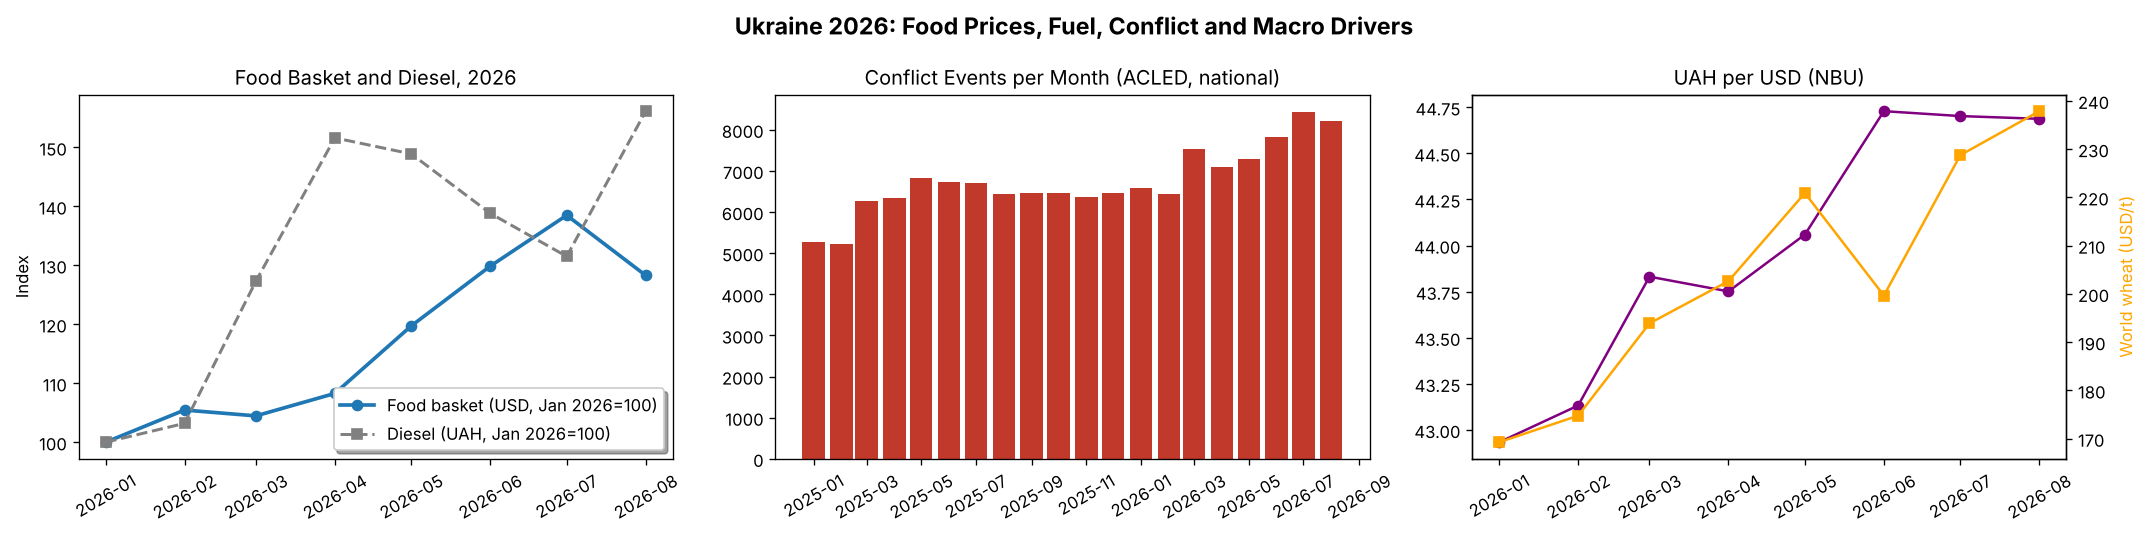

--- Ulusal Gıda Sepeti (USD, Ocak 2026 = 100) ---
            basket  diesel     fx   wheat
ym                                       
2026-01-01  100.00   58.73  42.93  169.25
2026-02-01  105.46   60.61  43.13  174.75
2026-03-01  104.47   74.77  43.83  193.88
2026-04-01  108.28   89.05  43.75  202.64
2026-05-01  119.74   87.45  44.06  220.88
2026-06-01  129.87   81.53  44.73  199.65
2026-07-01  138.50   77.24  44.70  228.74
2026-08-01  128.30   91.71  44.69  237.86

Ocak → Ağustos 2026: sepet +28.3%, mazot +56.2%, kur +4.1%, dünya buğdayı +40.5%


In [5]:
nat = panel.groupby('ym').agg(basket=('basket_usd', 'median'), diesel=('diesel_uah', 'median'), fx=('uah_per_usd', 'first'), wheat=('wheat_world_usd_t', 'first'))
ev = national['2025-01-01':'2026-08-01']
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), dpi=120)
axes[0].plot(nat.index, nat.basket, marker='o', lw=2.2, label='Food basket (USD, Jan 2026=100)')
axes[0].plot(nat.index, nat.diesel / nat.diesel.iloc[0] * 100, marker='s', ls='--', color='gray', lw=1.8, label='Diesel (UAH, Jan 2026=100)')
axes[0].set(title='Food Basket and Diesel, 2026', ylabel='Index'); axes[0].legend(frameon=True, shadow=True)
axes[1].bar(ev.index, ev.values, width=25, color='#c0392b'); axes[1].set(title='Conflict Events per Month (ACLED, national)')
axes[2].plot(nat.index, nat.fx, marker='o', color='purple'); axes[2].set(title='UAH per USD (NBU)')
a2 = axes[2].twinx(); a2.plot(nat.index, nat.wheat, marker='s', color='orange'); a2.set_ylabel('World wheat (USD/t)', color='orange')
for a in axes: a.tick_params(axis='x', rotation=30)
plt.suptitle('Ukraine 2026: Food Prices, Fuel, Conflict and Macro Drivers', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.savefig('fig1_national_2026.png', dpi=150); plt.show()

print("--- Ulusal Gıda Sepeti (USD, Ocak 2026 = 100) ---")
print(nat.round(2).to_string())
print(f"\nOcak → Ağustos 2026: sepet {nat.basket.iloc[-1]-100:+.1f}%, mazot {(nat.diesel.iloc[-1]/nat.diesel.iloc[0]-1)*100:+.1f}%, "
      f"kur {(nat.fx.iloc[-1]/nat.fx.iloc[0]-1)*100:+.1f}%, dünya buğdayı {(nat.wheat.iloc[-1]/nat.wheat.iloc[0]-1)*100:+.1f}%")

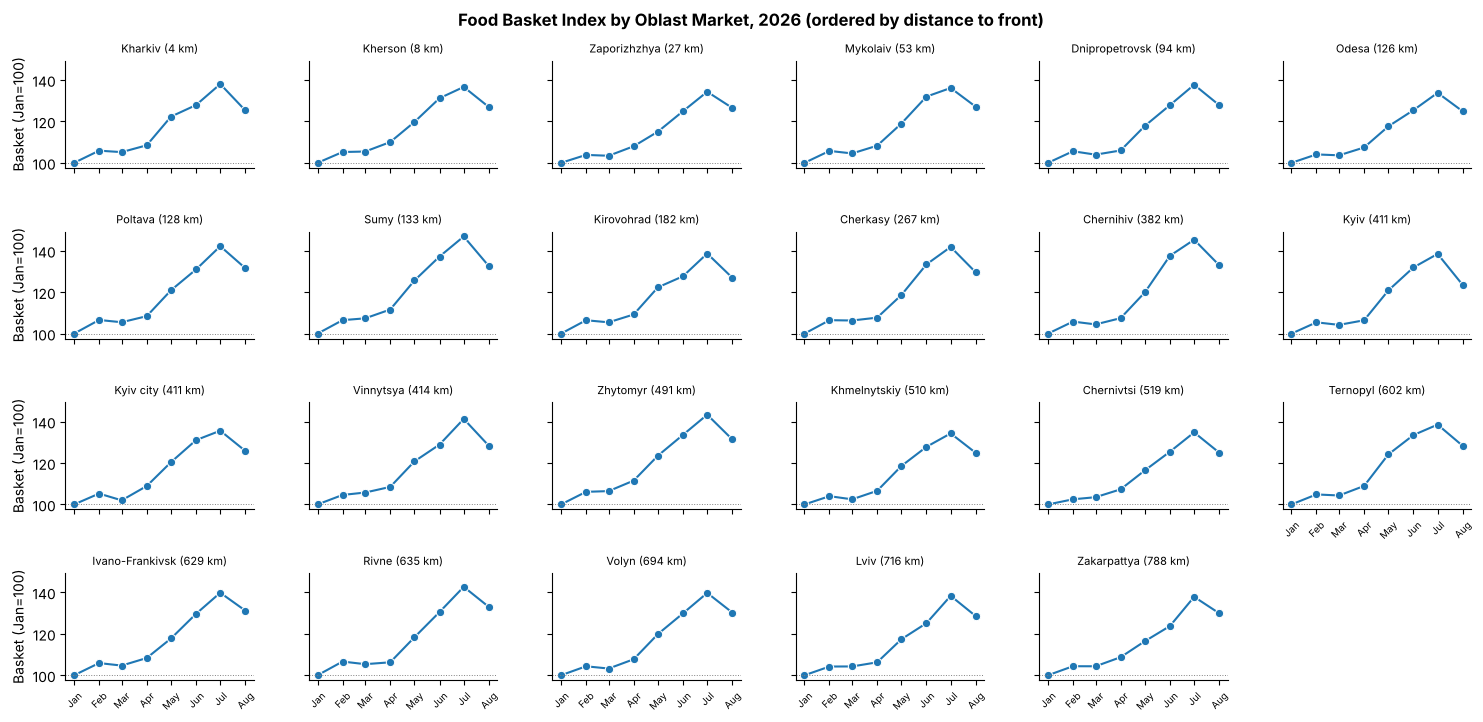

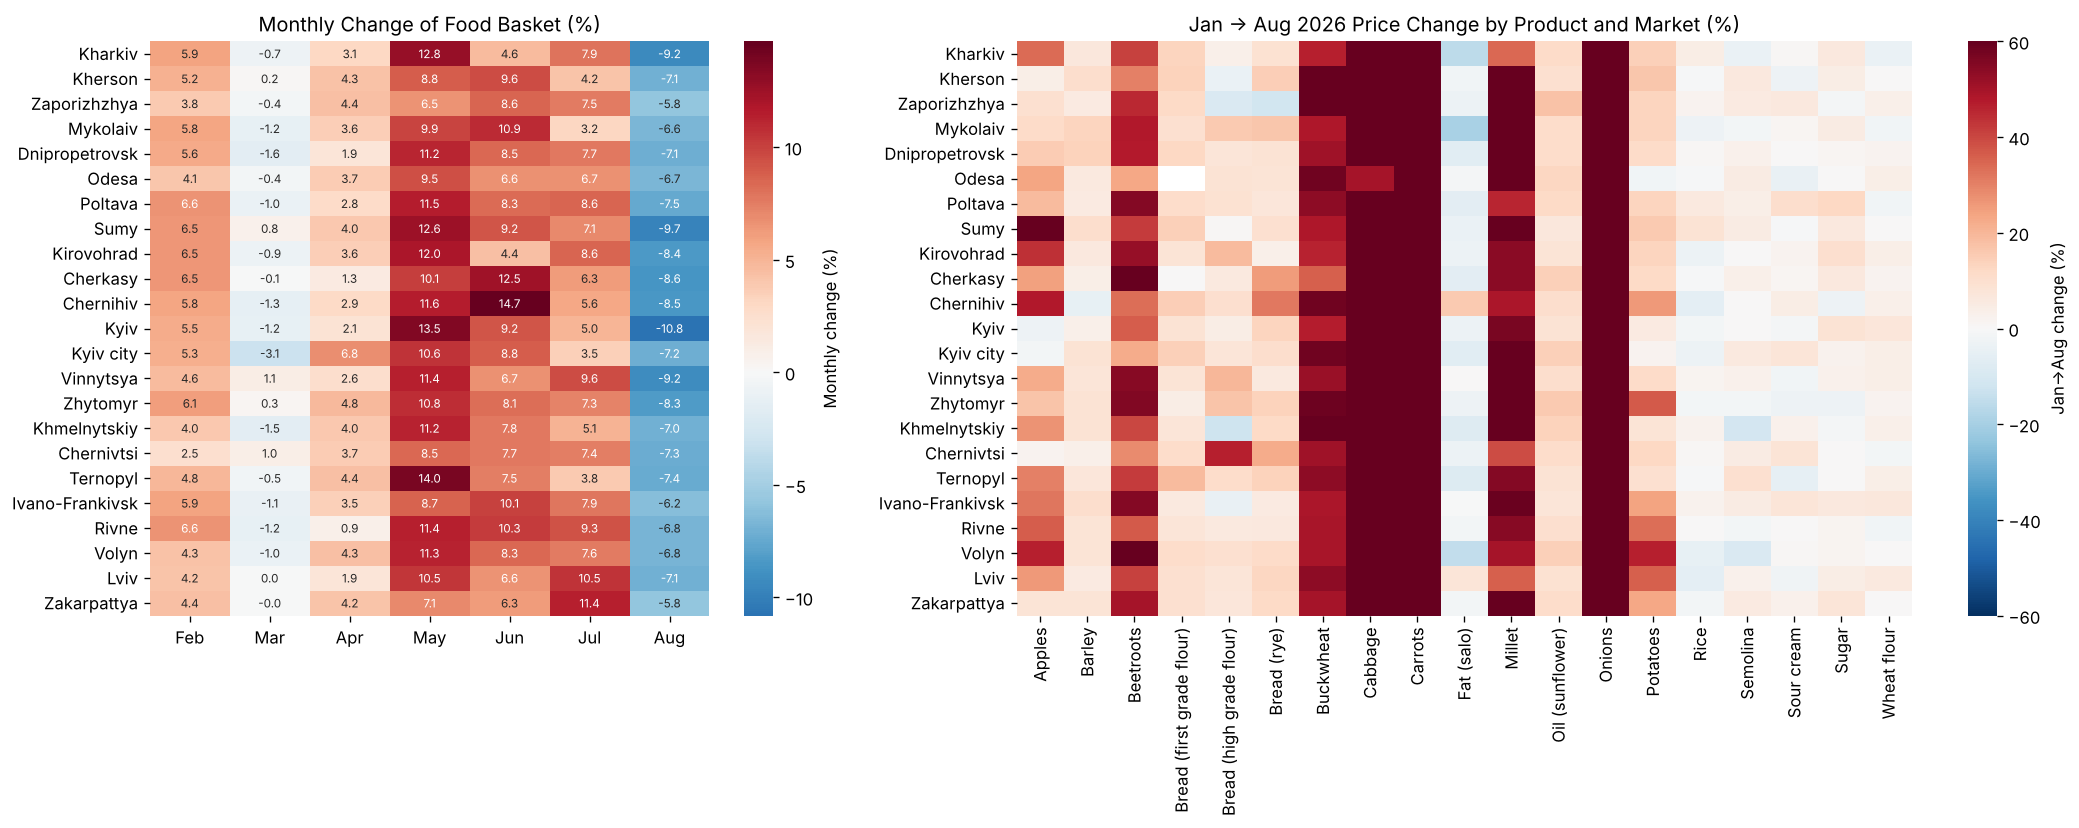

--- Bölgelere göre Ocak → Ağustos 2026 sepet değişimi (%) ---
market
Kharkiv            25.3
Kherson            27.0
Zaporizhzhya       26.5
Mykolaiv           27.1
Dnipropetrovsk     27.9
Odesa              24.9
Poltava            31.6
Sumy               32.6
Kirovohrad         27.0
Cherkasy           29.6
Chernihiv          33.0
Kyiv               23.5
Kyiv city          25.8
Vinnytsya          28.3
Zhytomyr           31.4
Khmelnytskiy       24.9
Chernivtsi         25.0
Ternopyl           28.3
Ivano-Frankivsk    31.2
Rivne              33.0
Volyn              30.3
Lviv               28.6
Zakarpattya        29.9

--- Ürünlere göre Ocak → Ağustos 2026 değişim (%), market medyanı ---
commodity
Onions                       226.3
Carrots                      108.0
Cabbage                      100.0
Millet                        59.2
Buckwheat                     50.9
Beetroots                     42.1
Apples                        23.9
Potatoes                      13.3
Bread (rye)       

In [6]:
import matplotlib.dates as mdates
order = mk.sort_values('dist_front_km').market.tolist()
dist = mk.set_index('market').dist_front_km

# Bölge bölge gıda sepeti (cepheye yakından uzağa)
g = sns.FacetGrid(panel, col='market', col_wrap=6, col_order=order, height=1.8, aspect=1.4, sharey=True)
g.map_dataframe(sns.lineplot, x='ym', y='basket_usd', marker='o', color='#1f77b4', lw=1.5)
for ax, m in zip(g.axes.flat, order):
    ax.set_title(f'{m} ({dist[m]:.0f} km)', fontsize=8); ax.axhline(100, color='gray', lw=.7, ls=':')
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b')); ax.tick_params(axis='x', labelsize=7, rotation=45)
g.set_axis_labels('', 'Basket (Jan=100)')
g.fig.suptitle('Food Basket Index by Oblast Market, 2026 (ordered by distance to front)', y=1.02, fontweight='bold')
plt.savefig('fig2_regions.png', dpi=150, bbox_inches='tight'); plt.show()

# Market x ay: aylık değişim ısı haritası
panel['mom'] = panel.groupby('market').basket_usd.pct_change() * 100
hm = panel.pivot_table(index='market', columns=panel.ym.dt.strftime('%b'), values='mom', sort=False).loc[order]
fig, axes = plt.subplots(1, 2, figsize=(18, 7), dpi=120, gridspec_kw={'width_ratios': [1, 1.6]})
sns.heatmap(hm.dropna(axis=1, how='all'), cmap='RdBu_r', center=0, annot=True, fmt='.1f', annot_kws={'size': 7}, ax=axes[0], cbar_kws={'label': 'Monthly change (%)'})
axes[0].set(title='Monthly Change of Food Basket (%)', xlabel='', ylabel='')
# Ürün x market: Ocak → Ağustos toplam değişim
chg = food[food.ym.isin([food.ym.min(), food.ym.max()])].pivot_table(index=['market', 'commodity'], columns='ym', values='price_usd')
chg = (chg.iloc[:, 1] / chg.iloc[:, 0] - 1).mul(100).unstack('commodity').loc[order]
sns.heatmap(chg, cmap='RdBu_r', center=0, vmin=-60, vmax=60, ax=axes[1], cbar_kws={'label': 'Jan→Aug change (%)'})
axes[1].set(title='Jan → Aug 2026 Price Change by Product and Market (%)', xlabel='', ylabel='')
plt.tight_layout(); plt.savefig('fig3_heatmaps.png', dpi=150); plt.show()

print("--- Bölgelere göre Ocak → Ağustos 2026 sepet değişimi (%) ---")
print((panel[panel.ym == panel.ym.max()].set_index('market').basket_usd - 100).loc[order].round(1).to_string())
print("\n--- Ürünlere göre Ocak → Ağustos 2026 değişim (%), market medyanı ---")
print(chg.median().sort_values(ascending=False).round(1).to_string())

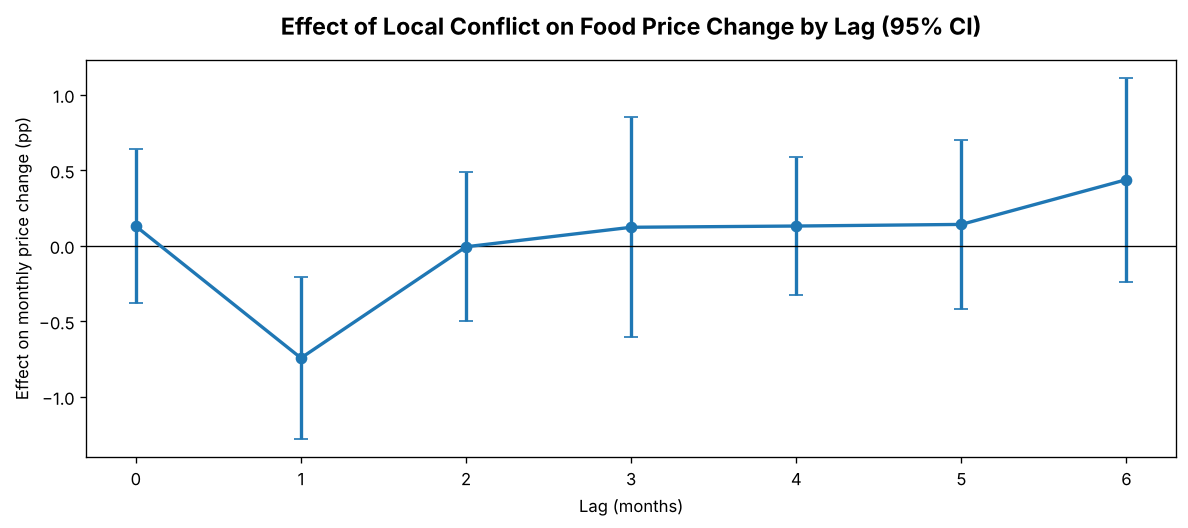

--- GECİKME ANALİZİ SONUÇLARI ---
Gözlem: 3052
 lag_month   beta  ci_low  ci_high  p_value
         0  0.129  -0.380    0.638    0.619
         1 -0.744  -1.282   -0.206    0.007
         2 -0.007  -0.500    0.487    0.978
         3  0.122  -0.606    0.850    0.742
         4  0.130  -0.326    0.587    0.576
         5  0.141  -0.417    0.699    0.620
         6  0.438  -0.237    1.113    0.204


In [7]:
import statsmodels.formula.api as smf

# Ürün x market x ay seviyesinde aylık fiyat değişimi
cm = df_cleaned[df_cleaned.category != 'non-food'].sort_values(['market', 'commodity', 'ym']).copy()
cm['d_price'] = cm.groupby(['market', 'commodity']).price_usd.transform(lambda s: np.log(s).diff() * 100)
cm = cm.merge(panel[['market', 'ym'] + [f'lev_l{k}' for k in range(7)] + ['dist_front_km']], on=['market', 'ym'], how='left')
cm['cxm'] = cm.commodity + '_' + cm.ym.dt.strftime('%m')
lag_df = cm.dropna(subset=['d_price'])

# Model: fiyat değişimi ~ yerel çatışma (0-6 ay gecikmeli) + market sabit etkisi + ürün x ay sabit etkisi
f = 'd_price ~ ' + ' + '.join(f'lev_l{k}' for k in range(7)) + ' + C(market) + C(cxm)'
m = smf.ols(f, lag_df).fit(cov_type='cluster', cov_kwds={'groups': lag_df.market.astype('category').cat.codes})
ci = m.conf_int()
lag_tbl = pd.DataFrame({'lag_month': range(7), 'beta': [m.params[f'lev_l{k}'] for k in range(7)],
                        'ci_low': [ci.loc[f'lev_l{k}', 0] for k in range(7)], 'ci_high': [ci.loc[f'lev_l{k}', 1] for k in range(7)],
                        'p_value': [m.pvalues[f'lev_l{k}'] for k in range(7)]})
plt.figure(figsize=(10, 4.5), dpi=120)
plt.errorbar(lag_tbl.lag_month, lag_tbl.beta, yerr=[lag_tbl.beta - lag_tbl.ci_low, lag_tbl.ci_high - lag_tbl.beta], fmt='o-', capsize=4, lw=2)
plt.axhline(0, color='k', lw=.8)
plt.title('Effect of Local Conflict on Food Price Change by Lag (95% CI)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Lag (months)'); plt.ylabel('Effect on monthly price change (pp)')
plt.tight_layout(); plt.savefig('fig4_lag_effects.png', dpi=150); plt.show()
print("--- GECİKME ANALİZİ SONUÇLARI ---")
print("Gözlem:", int(m.nobs))
print(lag_tbl.round(3).to_string(index=False))

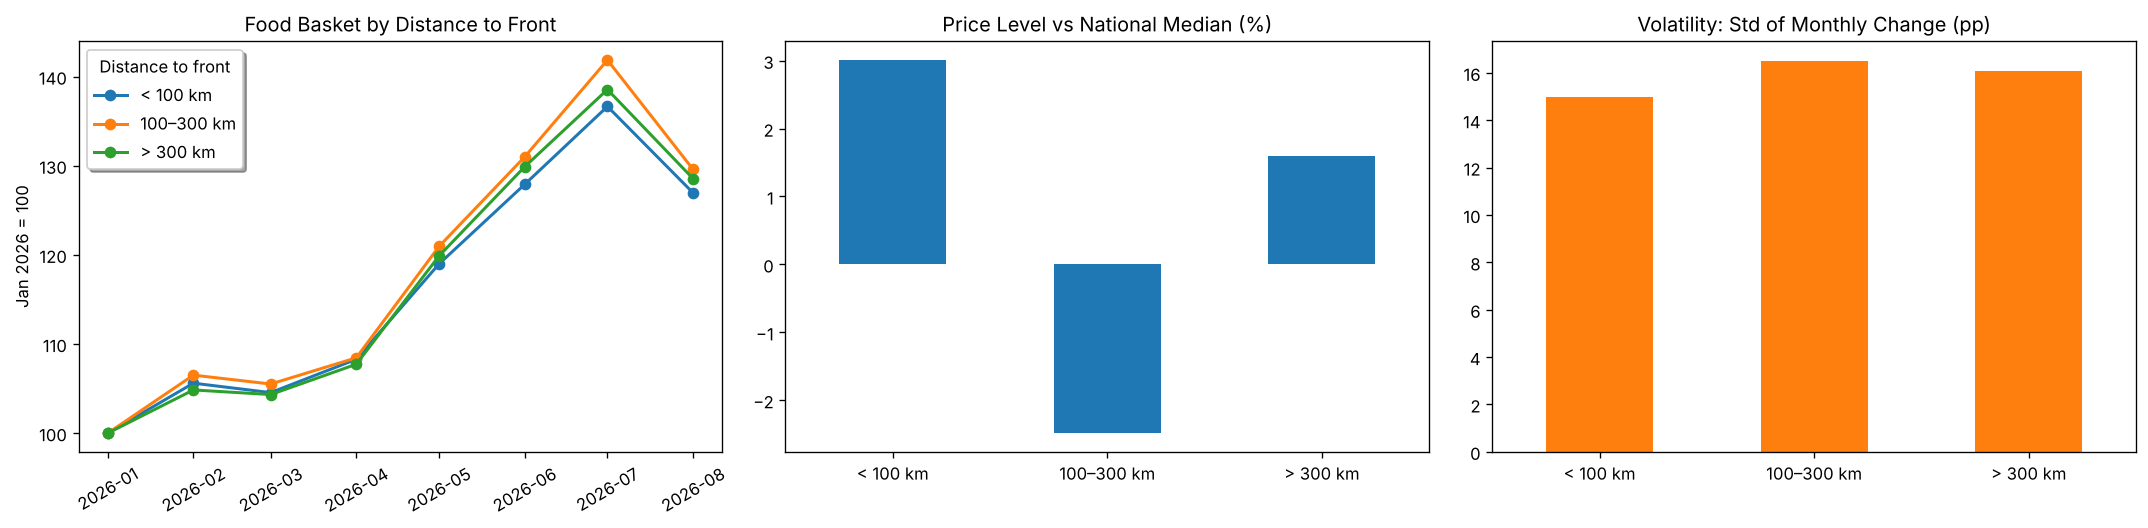

--- CEPHEYE YAKIN / UZAK ---
Sepet (Ocak = 100):
zone        < 100 km  100–300 km  > 300 km
ym                                        
2026-01-01     100.0       100.0     100.0
2026-02-01     105.6       106.5     104.8
2026-03-01     104.5       105.5     104.3
2026-04-01     108.3       108.4     107.7
2026-05-01     119.0       120.9     119.9
2026-06-01     127.9       131.0     129.9
2026-07-01     136.6       141.8     138.5
2026-08-01     127.0       129.6     128.6

Fiyat seviyesi, ülke medyanına göre (%):
zone
< 100 km      3.01
100–300 km   -2.49
> 300 km      1.59

Oynaklık (ürün bazında aylık değişimin std'si, pp):
zone
< 100 km      14.98
100–300 km    16.50
> 300 km      16.08

Ocak→Ağustos değişim ~ log(mesafe): eğim = 0.62, p = 0.15


In [8]:
panel['zone'] = pd.cut(panel.dist_front_km, [0, 100, 300, 1000], labels=['< 100 km', '100–300 km', '> 300 km'])
cm['zone'] = pd.cut(cm.dist_front_km, [0, 100, 300, 1000], labels=['< 100 km', '100–300 km', '> 300 km'])
zt = panel.groupby(['ym', 'zone']).basket_usd.median().unstack()
lvl = food.merge(mk[['market', 'dist_front_km']], on='market')
lvl['zone'] = pd.cut(lvl.dist_front_km, [0, 100, 300, 1000], labels=['< 100 km', '100–300 km', '> 300 km'])
lvl['rel'] = lvl.price_usd / lvl.groupby(['commodity', 'ym']).price_usd.transform('median') * 100
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), dpi=120)
for z in zt.columns: axes[0].plot(zt.index, zt[z], marker='o', lw=1.8, label=z)
axes[0].legend(title='Distance to front', frameon=True, shadow=True); axes[0].set(title='Food Basket by Distance to Front', ylabel='Jan 2026 = 100'); axes[0].tick_params(axis='x', rotation=30)
lvl.groupby('zone').rel.mean().sub(100).plot.bar(ax=axes[1], rot=0, color='#1f77b4'); axes[1].set(title='Price Level vs National Median (%)', xlabel='')
cm.groupby('zone').d_price.std().plot.bar(ax=axes[2], rot=0, color='#ff7f0e'); axes[2].set(title='Volatility: Std of Monthly Change (pp)', xlabel='')
plt.tight_layout(); plt.savefig('fig5_near_vs_far.png', dpi=150); plt.show()

print("--- CEPHEYE YAKIN / UZAK ---")
print("Sepet (Ocak = 100):"); print(zt.round(1).to_string())
print("\nFiyat seviyesi, ülke medyanına göre (%):"); print(lvl.groupby('zone').rel.mean().sub(100).round(2).to_string())
print("\nOynaklık (ürün bazında aylık değişimin std'si, pp):"); print(cm.groupby('zone').d_price.std().round(2).to_string())
last = panel[panel.ym == panel.ym.max()]
r = smf.ols('basket_usd ~ np.log(dist_front_km)', last).fit()
print(f"\nOcak→Ağustos değişim ~ log(mesafe): eğim = {r.params.iloc[1]:.2f}, p = {r.pvalues.iloc[1]:.2f}")

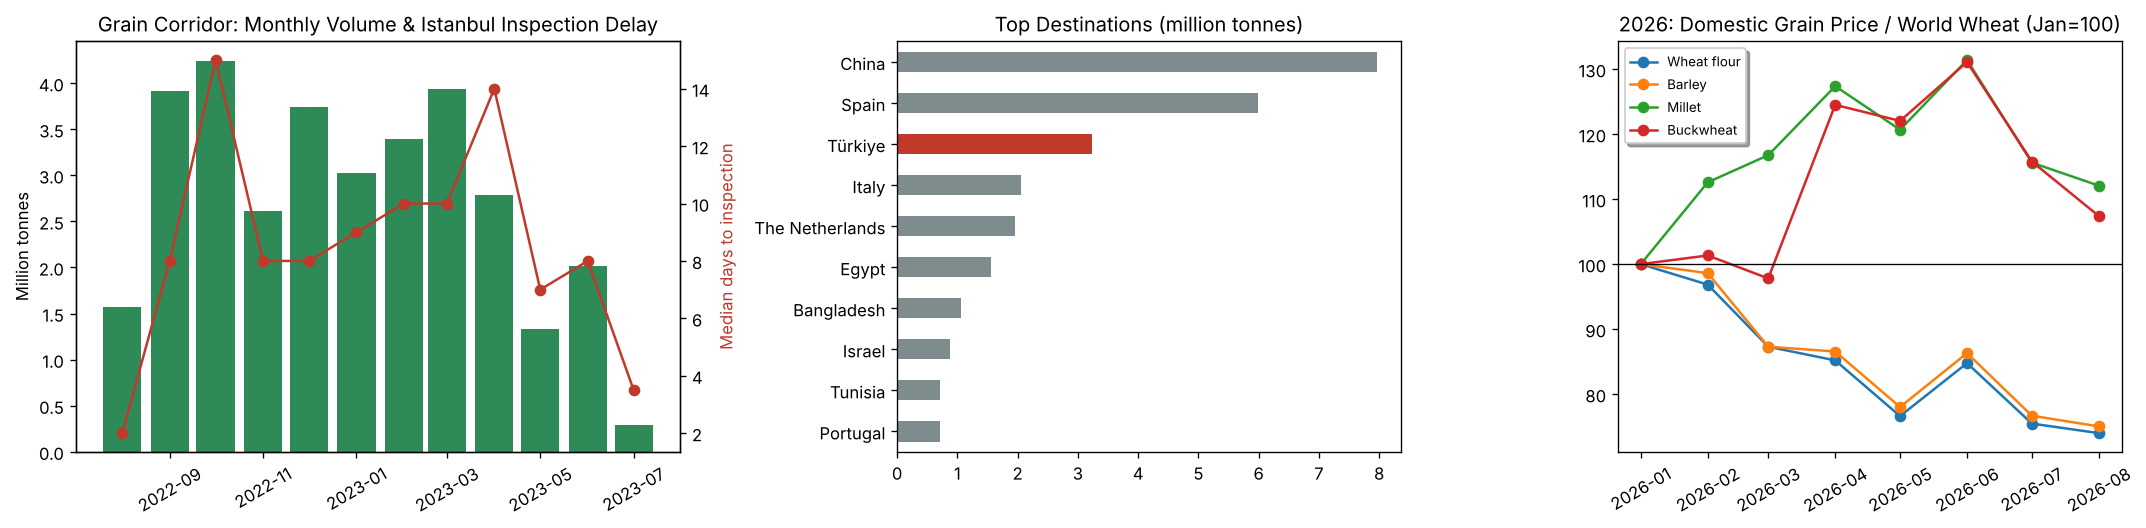

--- TAHIL KORİDORU ---
Toplam sevkiyat: 32.9 Mt | Sefer: 1004 | Limanlar: {'Chornomorsk': 448, 'Odesa': 382, 'Yuzhny/Pivdennyi': 314}
Ürünler (Mt): {'Corn': 16.9, 'Wheat': 8.91, 'Sunflower meal': 1.86, 'Sunflower oil': 1.65, 'Barley': 1.27}
Türkiye'ye giden: 3.24 Mt (#3 varış ülkesi)
Gelir grubuna göre pay: {'high-income': 0.44, 'low-income': 0.03, 'lower-middle income': 0.17, 'upper-middle-income': 0.37}

İstanbul denetim bekleme süresi (gün, aylık medyan):
            ships  wait_median   Mt
dep                                
2022-08-01     63          2.0  1.6
2022-09-01    178          8.0  3.9
2022-10-01    180         15.0  4.2
2022-11-01     85          8.0  2.6
2022-12-01    106          8.0  3.7
2023-01-01     78          9.0  3.0
2023-02-01     83         10.0  3.4
2023-03-01     88         10.0  3.9
2023-04-01     64         14.0  2.8
2023-05-01     33          7.0  1.3
2023-06-01     38          8.0  2.0
2023-07-01      8          3.5  0.3

2026 iç fiyat / dünya buğday fiy

In [9]:
# Karadeniz Tahıl Koridoru (Ağu 2022 - Tem 2023) ve Türkiye'nin rolü
v = bsgi.drop_duplicates('Outbound Sequence').assign(wait=lambda d: (d.insp - d.dep).dt.days)
mon = v.groupby(v.dep.dt.to_period('M').dt.to_timestamp()).agg(ships=('wait', 'size'), wait_median=('wait', 'median'))
mon['Mt'] = bsgi.groupby(bsgi.dep.dt.to_period('M').dt.to_timestamp()).tonnage.sum() / 1e6
dest = (bsgi.groupby('Country').tonnage.sum() / 1e6).sort_values(ascending=False)
cargo = (bsgi.groupby('Commodity').tonnage.sum() / 1e6).sort_values(ascending=False)

# 2026: Ukrayna içindeki tahıl fiyatları / dünya buğday fiyatı (Ocak 2026 = 100)
wh = nat.wheat / nat.wheat.iloc[0]
ratio = {}
for com in ['Wheat flour', 'Barley', 'Millet', 'Buckwheat']:
    s = df_cleaned[df_cleaned.commodity == com].groupby('ym').price_usd.median()
    ratio[com] = (s / s.iloc[0]) / wh * 100
ratio = pd.DataFrame(ratio)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), dpi=120, gridspec_kw={'width_ratios': [1.2, 1, 1]})
axes[0].bar(mon.index, mon.Mt, width=25, color='#2e8b57'); axes[0].set(title='Grain Corridor: Monthly Volume & Istanbul Inspection Delay', ylabel='Million tonnes')
a2 = axes[0].twinx(); a2.plot(mon.index, mon.wait_median, 'o-', color='#c0392b'); a2.set_ylabel('Median days to inspection', color='#c0392b')
axes[0].tick_params(axis='x', rotation=30)
dest.head(10)[::-1].plot.barh(ax=axes[1], color=['#c0392b' if c == 'Türkiye' else '#7f8c8d' for c in dest.head(10).index[::-1]])
axes[1].set(title='Top Destinations (million tonnes)', ylabel='')
for c in ratio: axes[2].plot(ratio.index, ratio[c], marker='o', label=c)
axes[2].axhline(100, color='k', lw=.8); axes[2].legend(frameon=True, shadow=True, fontsize=8)
axes[2].set(title='2026: Domestic Grain Price / World Wheat (Jan=100)'); axes[2].tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.savefig('fig6_grain_corridor.png', dpi=150); plt.show()

print("--- TAHIL KORİDORU ---")
print(f"Toplam sevkiyat: {bsgi.tonnage.sum()/1e6:.1f} Mt | Sefer: {len(v)} | Limanlar: {bsgi['Departure port'].value_counts().to_dict()}")
print("Ürünler (Mt):", cargo.head(5).round(2).to_dict())
print(f"Türkiye'ye giden: {dest['Türkiye']:.2f} Mt (#{list(dest.index).index('Türkiye')+1} varış ülkesi)")
print("Gelir grubuna göre pay:", (bsgi.groupby('Income group').tonnage.sum() / bsgi.tonnage.sum()).round(2).to_dict())
print("\nİstanbul denetim bekleme süresi (gün, aylık medyan):"); print(mon.round(1).to_string())
print("\n2026 iç fiyat / dünya buğday fiyatı (Ocak = 100):"); print(ratio.round(1).to_string())

In [10]:
# Ürün x market x ay tablosu: fiyat değişimleri ve gecikmeli ek veriler (erken uyarı modelinde de kullanılır)
fp = df_cleaned[df_cleaned.category != 'non-food'].groupby(['market', 'commodity', 'ym'], as_index=False).price_usd.mean()
fp = fp.sort_values(['market', 'commodity', 'ym']); g = fp.groupby(['market', 'commodity'])
fp['lag1_price'] = g.price_usd.shift(1)
fp['chg_l1'] = np.log(g.price_usd.shift(1) / g.price_usd.shift(2))
fp['nat_chg_l1'] = fp.groupby(['commodity', 'ym']).chg_l1.transform('median')
fp['y'] = np.log(fp.price_usd / fp.lag1_price)

q = panel.sort_values(['market', 'ym']).copy(); pg = q.groupby('market')
q['events_l1'] = pg.lev_l0.shift(1); q['nat_ev_chg_l1'] = pg.nat_ev_chg.shift(1)
q['fx_chg_l1'] = np.log(pg.uah_per_usd.shift(1) / pg.uah_per_usd.shift(2))
q['diesel_chg_l1'] = np.log(pg.diesel_uah.shift(1) / pg.diesel_uah.shift(2))
q['wheat_chg_l1'] = np.log(pg.wheat_world_usd_t.shift(1) / pg.wheat_world_usd_t.shift(2))
# Ocak 2025 verisi olmadığı için Şubat satırlarında gecikmeli makro değişimler: kur ve buğday dış kaynaktan gelir
fxm = fx.set_index('ym').uah_per_usd; whm = wheat.set_index('ym').wheat_world_usd_t
q['fx_chg_l1'] = q.ym.map(lambda t: np.log(fxm[t - pd.DateOffset(months=1)] / fxm[t - pd.DateOffset(months=2)]))
q['wheat_chg_l1'] = q.ym.map(lambda t: np.log(whm[t - pd.DateOffset(months=1)] / whm[t - pd.DateOffset(months=2)]))
fp = fp.merge(q[['market', 'ym', 'events_l1', 'nat_ev_chg_l1', 'fx_chg_l1', 'diesel_chg_l1', 'wheat_chg_l1', 'dist_front_km']], on=['market', 'ym'])
fp['market_encoded'] = fp.market.astype('category').cat.codes
fp['commodity_encoded'] = fp.commodity.astype('category').cat.codes
fp['month'] = fp.ym.dt.month
fp['no_history'] = fp.chg_l1.isna().astype(int)
fp[['chg_l1', 'nat_chg_l1', 'diesel_chg_l1']] = fp[['chg_l1', 'nat_chg_l1', 'diesel_chg_l1']].fillna(0)
fp = fp.dropna(subset=['y'])


# --- Fiyat seviyesi modeli: ilk modelin özellikleri + ek veri setlerinden gelen özellikler
mdf = df_cleaned.merge(panel[['market', 'ym', 'lev_l0', 'lev_l1', 'nat_ev_chg', 'dist_front_km', 'uah_per_usd',
                              'wheat_world_usd_t', 'diesel_uah']], on=['market', 'ym'])
F_ORIG = ['market_encoded', 'commodity_encoded', 'year', 'month', 'latitude', 'longitude']
F_NEW = F_ORIG + ['lev_l0', 'lev_l1', 'nat_ev_chg', 'dist_front_km', 'uah_per_usd', 'wheat_world_usd_t', 'diesel_uah']
def rf():
    return RandomForestRegressor(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1)

rows, lomo = [], {}
for name, F in [('İlk model (market, ürün, tarih, konum)', F_ORIG), ('Yeni model (+ çatışma, cephe, kur, buğday, mazot)', F_NEW)]:
    # (a) İlk modeldeki gibi rastgele %80/%20 ayırma
    Xtr, Xte, ytr, yte = train_test_split(mdf[F], mdf.price_usd, test_size=0.2, random_state=42)
    pr = rf().fit(Xtr, ytr).predict(Xte)
    # (b) Bir ayı dışarıda bırak: her ay, o ayı hiç görmemiş bir modelle tahmin edilir
    out = [mdf[mdf.ym == t].assign(pred=rf().fit(mdf[mdf.ym != t][F], mdf[mdf.ym != t].price_usd).predict(mdf[mdf.ym == t][F]))
           for t in sorted(mdf.ym.unique())]
    lomo[name] = pd.concat(out)
    rows.append({'Model': name,
                 'MAE rastgele': mean_absolute_error(yte, pr), 'RMSE rastgele': np.sqrt(mean_squared_error(yte, pr)),
                 'MAE ay dışarıda': mean_absolute_error(lomo[name].price_usd, lomo[name].pred),
                 'RMSE ay dışarıda': np.sqrt(mean_squared_error(lomo[name].price_usd, lomo[name].pred))})
print("--- FİYAT TAHMİN MODELİ SONUÇLARI (USD) ---")
print(pd.DataFrame(rows).round(4).to_string(index=False))
nv = fp.dropna(subset=['lag1_price'])
print(f"\nKarşılaştırma, 'geçen ayın fiyatı' tahmini (Şubat–Ağustos): MAE {mean_absolute_error(nv.price_usd, nv.lag1_price):.4f} USD")
final_rf = rf().fit(mdf[F_NEW], mdf.price_usd)
print("\nYeni modelde özellik önemleri:"); print(pd.Series(final_rf.feature_importances_, index=F_NEW).sort_values(ascending=False).round(3).to_string())

--- FİYAT TAHMİN MODELİ SONUÇLARI (USD) ---
                                            Model  MAE rastgele  RMSE rastgele  MAE ay dışarıda  RMSE ay dışarıda
           İlk model (market, ürün, tarih, konum)        0.0423         0.0840           0.0616            0.1206
Yeni model (+ çatışma, cephe, kur, buğday, mazot)        0.0496         0.1042           0.0622            0.1169

Karşılaştırma, 'geçen ayın fiyatı' tahmini (Şubat–Ağustos): MAE 0.0603 USD



Yeni modelde özellik önemleri:
commodity_encoded    0.967
market_encoded       0.006
diesel_uah           0.005
latitude             0.005
dist_front_km        0.004
longitude            0.003
uah_per_usd          0.002
month                0.002
lev_l0               0.002
lev_l1               0.002
wheat_world_usd_t    0.001
nat_ev_chg           0.000
year                 0.000


Sıçrama eşiği: gelecek ay +8.4% ve üzeri | satır: 2616 | pozitif oran: %15



--- ERKEN UYARI MODELİ SONUÇLARI (test: tahmin ayları Nisan–Temmuz 2026) ---
                  Özellikler               Model  ROC-AUC  PR-AUC
               Fiyat geçmişi Logistic Regression    0.642   0.353
               Fiyat geçmişi       Random Forest    0.644   0.285
+ Makro (kur, yakıt, buğday) Logistic Regression    0.621   0.337
+ Makro (kur, yakıt, buğday)       Random Forest    0.620   0.306
     + Çatışma (ACLED, UCDP) Logistic Regression    0.643   0.340
     + Çatışma (ACLED, UCDP)       Random Forest    0.622   0.264
                       Hepsi Logistic Regression    0.630   0.323
                       Hepsi       Random Forest    0.624   0.293

Alarm eşiği 0.17: precision 0.30, recall 0.59 (rastgele precision: 0.18)


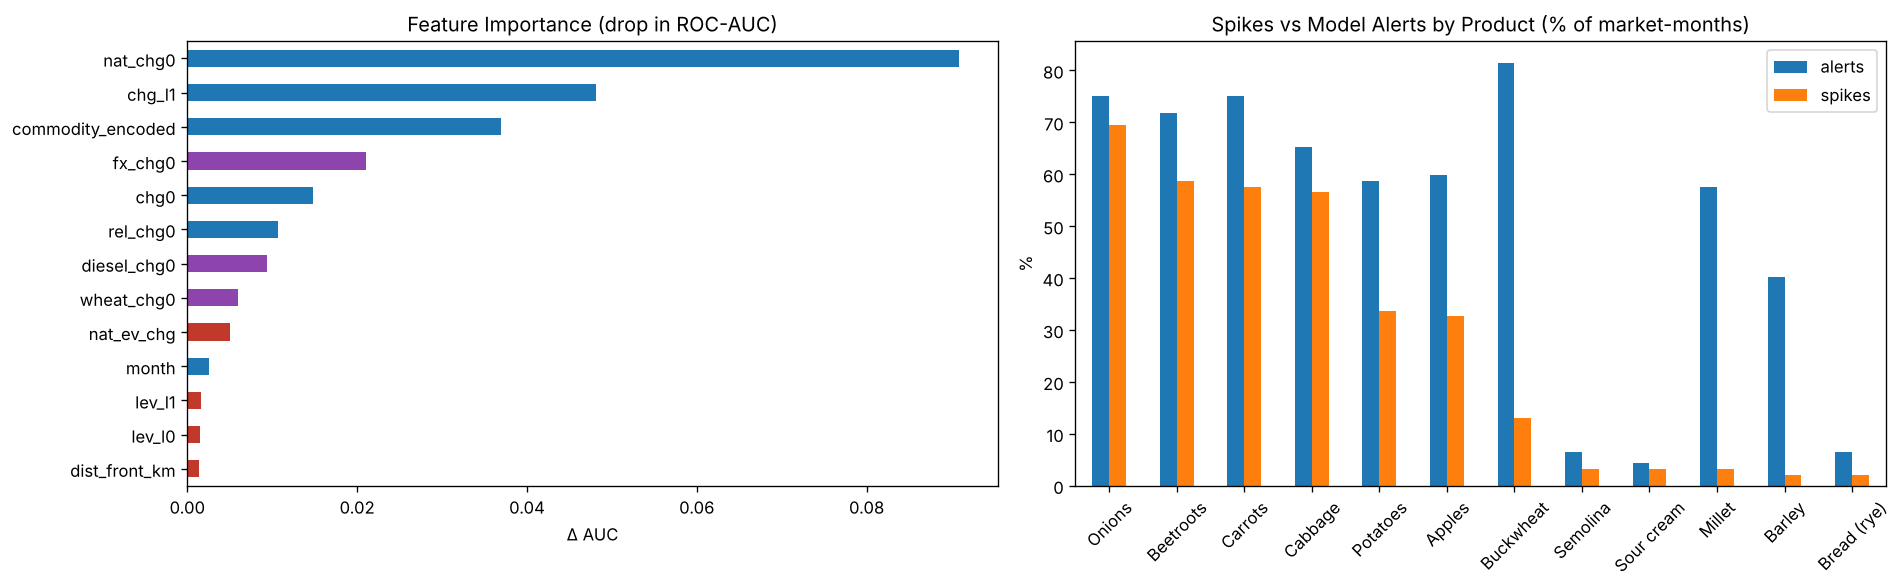

In [11]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, precision_score, recall_score

# Erken uyarı: "Gelecek ay bu üründe bu markette fiyat sıçraması olacak mı?"
ew = fp.sort_values(['market', 'commodity', 'ym']).copy()
ew['chg0'] = ew.y                                                    # bu ayki değişim (biliniyor)
ew['next_chg'] = ew.groupby(['market', 'commodity']).y.shift(-1)     # gelecek ayki değişim (hedef)
ew['nat_chg0'] = ew.groupby(['commodity', 'ym']).chg0.transform('median')
ew['rel_chg0'] = ew.chg0 - ew.nat_chg0
qq = panel[['market', 'ym', 'lev_l0', 'lev_l1', 'nat_ev_chg', 'diesel_uah', 'uah_per_usd', 'wheat_world_usd_t']].sort_values(['market', 'ym']).copy()
qq['diesel_chg0'] = np.log(qq.diesel_uah / qq.groupby('market').diesel_uah.shift(1))
qq['fx_chg0'] = qq.ym.map(lambda t: np.log(fxm[t] / fxm[t - pd.DateOffset(months=1)]))
qq['wheat_chg0'] = qq.ym.map(lambda t: np.log(whm[t] / whm[t - pd.DateOffset(months=1)]))
ew = ew.merge(qq[['market', 'ym', 'lev_l0', 'lev_l1', 'nat_ev_chg', 'diesel_chg0', 'fx_chg0', 'wheat_chg0']], on=['market', 'ym'])
ew = ew.dropna(subset=['next_chg'])
THR = ew.next_chg.quantile(.85)
ew['spike'] = (ew.next_chg >= THR).astype(int)
print(f"Sıçrama eşiği: gelecek ay +{(np.exp(THR)-1)*100:.1f}% ve üzeri | satır: {len(ew)} | pozitif oran: %{ew.spike.mean()*100:.0f}")

E_BASE = ['commodity_encoded', 'month', 'chg0', 'chg_l1', 'nat_chg0', 'rel_chg0']
E_MACRO = ['fx_chg0', 'diesel_chg0', 'wheat_chg0']
E_CONF = ['lev_l0', 'lev_l1', 'nat_ev_chg', 'dist_front_km']
groups = [('Fiyat geçmişi', E_BASE), ('+ Makro (kur, yakıt, buğday)', E_BASE + E_MACRO),
          ('+ Çatışma (ACLED, UCDP)', E_BASE + E_CONF), ('Hepsi', E_BASE + E_MACRO + E_CONF)]
def rf_clf(): return RandomForestClassifier(n_estimators=400, min_samples_leaf=10, random_state=0, n_jobs=-1)

# İleriye doğru doğrulama: Nisan–Temmuz 2026 tahmin ayları (her biri yalnızca önceki aylarla eğitilir)
test_months = sorted(ew.ym.unique())[2:]
rows, store = [], {}
for name, F in groups:
    for mname, make in [('Logistic Regression', lambda: LogisticRegression(max_iter=3000, C=.5)), ('Random Forest', rf_clf)]:
        out = []
        for t in test_months:
            tr, te = ew[ew.ym < t], ew[ew.ym == t]
            mdl = make().fit(tr[F].fillna(0), tr.spike)
            out.append(te.assign(prob=mdl.predict_proba(te[F].fillna(0))[:, 1]))
        out = pd.concat(out); store[(name, mname)] = out
        rows.append({'Özellikler': name, 'Model': mname, 'ROC-AUC': roc_auc_score(out.spike, out.prob), 'PR-AUC': average_precision_score(out.spike, out.prob)})
print("\n--- ERKEN UYARI MODELİ SONUÇLARI (test: tahmin ayları Nisan–Temmuz 2026) ---")
print(pd.DataFrame(rows).round(3).to_string(index=False))

best = store[('Hepsi', 'Random Forest')]
cut = best.prob.quantile(1 - 2 * best.spike.mean())
best = best.assign(alert=(best.prob >= cut).astype(int))
print(f"\nAlarm eşiği {cut:.2f}: precision {precision_score(best.spike, best.alert):.2f}, recall {recall_score(best.spike, best.alert):.2f} (rastgele precision: {best.spike.mean():.2f})")

from sklearn.inspection import permutation_importance
F_all = E_BASE + E_MACRO + E_CONF
last_t = test_months[-1]
mdl = rf_clf().fit(ew[ew.ym < last_t][F_all].fillna(0), ew[ew.ym < last_t].spike)
te = ew[ew.ym >= test_months[0]]
pi = permutation_importance(mdl, te[F_all].fillna(0), te.spike, scoring='roc_auc', n_repeats=10, random_state=0)
imp = pd.Series(pi.importances_mean, index=F_all).sort_values()
colors = ['#8e44ad' if f in E_MACRO else '#c0392b' if f in E_CONF else '#1f77b4' for f in imp.index]
cat_rate = best.groupby(best.commodity).agg(alerts=('alert', 'mean'), spikes=('spike', 'mean')).sort_values('spikes', ascending=False).head(12)
fig, axes = plt.subplots(1, 2, figsize=(16, 5), dpi=120)
imp.plot.barh(ax=axes[0], color=colors); axes[0].set(title='Feature Importance (drop in ROC-AUC)', xlabel='Δ AUC')
cat_rate.mul(100).plot.bar(ax=axes[1], rot=45); axes[1].set(title='Spikes vs Model Alerts by Product (% of market-months)', xlabel='', ylabel='%')
plt.tight_layout(); plt.savefig('fig7_early_warning.png', dpi=150); plt.show()

In [12]:
import re
# Aynı yaklaşım Suriye, Yemen ve Sudan'da (aynı WFP kaynağı ve aynı temizlik adımı, 2026)
gl = pd.read_csv('data/wfp_syr_yem_sdn_2026.csv')
def norm(s):
    s = re.sub(r"^(al|ar|as|ad|an|ash|at)[ -]", "", str(s).lower()); return re.sub(r"[^a-z]", "", s)

def country_frame(code, acled_file):
    d = gl[gl.country_code == code].dropna(subset=['price_usd', 'local_price']).copy()
    d = d[(d.category != 'non-food') & (d.price_type == 'Retail')]
    d['ym'] = pd.to_datetime(d.date).dt.to_period('M').dt.to_timestamp()
    d = d.groupby(['market', 'county', 'commodity', 'ym'], as_index=False).price_usd.mean().sort_values(['market', 'commodity', 'ym'])
    gg = d.groupby(['market', 'commodity'])
    d['chg0'] = np.log(d.price_usd / gg.price_usd.shift(1)); d['chg_l1'] = gg.chg0.shift(1)
    d['next_chg'] = gg.chg0.shift(-1)
    d['nat_chg0'] = d.groupby(['commodity', 'ym']).chg0.transform('median'); d['rel_chg0'] = d.chg0 - d.nat_chg0
    ac = read_acled(f'data/{acled_file}'); amap = {norm(a): a for a in ac.Admin1.unique()}
    d['acled_admin1'] = d.county.map(lambda s: amap.get(norm(s)))
    ac = ac.rename(columns={'Admin1': 'acled_admin1'}).sort_values(['acled_admin1', 'ym'])
    ac['lev_l0'] = np.log1p(ac.Events); ac['lev_l1'] = ac.groupby('acled_admin1').lev_l0.shift(1)
    d = d.merge(ac[['acled_admin1', 'ym', 'lev_l0', 'lev_l1']], on=['acled_admin1', 'ym'], how='left')
    d[['lev_l0', 'lev_l1']] = d[['lev_l0', 'lev_l1']].fillna(0)
    d['month'] = d.ym.dt.month
    d = d.replace([np.inf, -np.inf], np.nan).dropna(subset=['chg0', 'next_chg'])
    d['local_spike'] = ((d.next_chg - d.groupby(['commodity', 'ym']).next_chg.transform('median')) >= 0).astype(int)
    return d

# Hedef: gelecek ay ürünün bu markette ülke medyanından belirgin fazla artması (yerel sıçrama, her ülkenin kendi %85'lik dilimi)
def local_target(d):
    rel = d.next_chg - d.groupby(['commodity', 'ym']).next_chg.transform('median')
    d = d.assign(rel_next=rel); d['spike'] = (d.rel_next >= d.rel_next.quantile(.85)).astype(int); return d

ukr_t = local_target(ew.copy())
others = {c: local_target(country_frame(code, f)) for c, code, f in [('Syria', 'SYR', 'acled_syria_pv.xlsx'), ('Yemen', 'YEM', 'acled_yemen_pv.xlsx'), ('Sudan', 'SDN', 'acled_sudan_pv.xlsx')]}
for c, d in others.items():
    print(f"{c}: {len(d)} satır, {d.market.nunique()} market, {d.commodity.nunique()} ürün, ACLED eşleşme %{d.lev_l0.gt(0).mean()*100:.0f} (olay>0)")

P_F = ['month', 'chg0', 'chg_l1', 'nat_chg0', 'rel_chg0']
P_FC = P_F + ['lev_l0', 'lev_l1']
rows = []
for F, tag in [(P_F, 'fiyat'), (P_FC, 'fiyat + çatışma')]:
    m_ukr = rf_clf().fit(ukr_t[F].fillna(0), ukr_t.spike)
    for c, d in others.items():
        mths = sorted(d.ym.unique()); split = mths[len(mths) // 2]
        tr, te = d[d.ym < split], d[d.ym >= split]
        rows.append({'Ülke': c, 'Özellikler': tag,
                     'Kendi verisiyle AUC': roc_auc_score(te.spike, rf_clf().fit(tr[F].fillna(0), tr.spike).predict_proba(te[F].fillna(0))[:, 1]),
                     'Ukrayna modeli AUC': roc_auc_score(te.spike, m_ukr.predict_proba(te[F].fillna(0))[:, 1])})
print("\n--- AKTARIM TESTİ (ROC-AUC) ---")
print(pd.DataFrame(rows).pivot(index='Ülke', columns='Özellikler').round(3))

rows = []
for c, d in {'Ukraine': cm.dropna(subset=['d_price']).assign(chg=lambda x: x.d_price / 100, lev_l0=lambda x: x.lev_l0, lev_l1=lambda x: x.lev_l1), **{k: v.assign(chg=v.chg0) for k, v in others.items()}}.items():
    d = d.assign(cxm=d.commodity + '_' + d.ym.dt.strftime('%m'), chg=d.chg * 100)
    mm = smf.ols('chg ~ lev_l0 + lev_l1 + C(market) + C(cxm)', d).fit(cov_type='cluster', cov_kwds={'groups': d.market.astype('category').cat.codes})
    rows.append({'Ülke': c, 'n': int(mm.nobs), 'lag0 beta (p)': f"{mm.params['lev_l0']:.2f} ({mm.pvalues['lev_l0']:.2f})", 'lag1 beta (p)': f"{mm.params['lev_l1']:.2f} ({mm.pvalues['lev_l1']:.2f})"})
print("\n--- Yerel çatışma -> fiyat değişimi, dört ülke ---")
print(pd.DataFrame(rows).set_index('Ülke'))

Syria: 9699 satır, 71 market, 24 ürün, ACLED eşleşme %98 (olay>0)
Yemen: 840 satır, 11 market, 13 ürün, ACLED eşleşme %46 (olay>0)
Sudan: 746 satır, 16 market, 10 ürün, ACLED eşleşme %74 (olay>0)



--- AKTARIM TESTİ (ROC-AUC) ---
           Kendi verisiyle AUC                 Ukrayna modeli AUC  \
Özellikler               fiyat fiyat + çatışma              fiyat   
Ülke                                                                
Sudan                    0.619           0.615              0.685   
Syria                    0.663           0.667              0.656   
Yemen                    0.724           0.736              0.753   

                            
Özellikler fiyat + çatışma  
Ülke                        
Sudan                0.681  
Syria                0.664  
Yemen                0.742  



--- Yerel çatışma -> fiyat değişimi, dört ülke ---
            n lag0 beta (p) lag1 beta (p)
Ülke                                     
Ukraine  3052   0.06 (0.81)  -0.73 (0.02)
Syria    9699  -1.65 (0.03)   1.13 (0.05)
Yemen     840   0.92 (0.05)   2.96 (0.00)
Sudan     746   5.60 (0.20)  -0.19 (0.94)


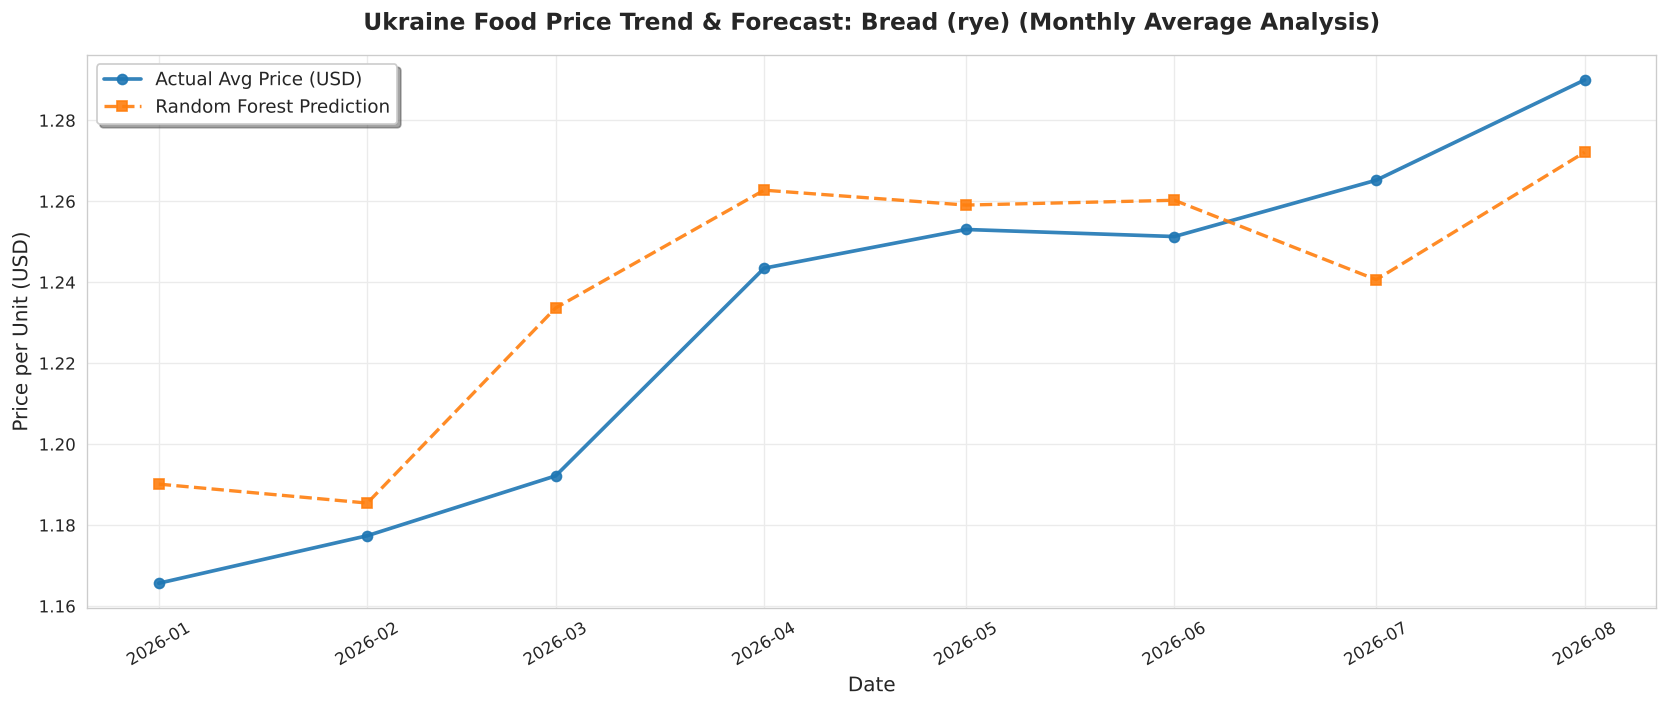

        ym  price_usd  predicted_usd
2026-01-01      1.166          1.190
2026-02-01      1.177          1.185
2026-03-01      1.192          1.234
2026-04-01      1.243          1.263
2026-05-01      1.253          1.259
2026-06-01      1.251          1.260
2026-07-01      1.265          1.241
2026-08-01      1.290          1.272

Bread (rye) MAE: 0.0438 USD


In [13]:
# 1. Belirli bir ürün seçelim (Örn: Çavdar Ekmeği - Bread (rye))
target_commodity = 'Bread (rye)'
commodity_df = fp[fp['commodity'] == target_commodity].copy()
actual = df_cleaned[df_cleaned.commodity == target_commodity].groupby('ym').price_usd.mean()

# Tahminler market bazında yapıldı ("bir ayı dışarıda bırak": her ayın tahmini o ayı görmemiş modelden), sonra aylık ortalaması alındı
best_lomo = lomo['Yeni model (+ çatışma, cephe, kur, buğday, mazot)']
pred = best_lomo[best_lomo.commodity == target_commodity].groupby('ym').pred.mean()
daily_avg = pd.DataFrame({'price_usd': actual, 'predicted_usd': pred}).reset_index()

# 2. Profesyonel ve Okunabilir Grafik Çizimi
plt.figure(figsize=(14, 6), dpi=120)
sns.set_style("whitegrid", {'grid.color': '.92'})

# Gerçek Ortalama Fiyatlar (Mavi Düz Çizgi)
plt.plot(daily_avg['ym'], daily_avg['price_usd'],
         marker='o', linestyle='-', color='#1f77b4', linewidth=2.2, label='Actual Avg Price (USD)', alpha=0.9)

# Random Forest Tahmini (Turuncu Kesikli/İşaretli Çizgi)
plt.plot(daily_avg['ym'], daily_avg['predicted_usd'],
         marker='s', linestyle='--', color='#ff7f0e', linewidth=2, label='Random Forest Prediction', alpha=0.9)

# Başlık ve Etiketler
plt.title(f'Ukraine Food Price Trend & Forecast: {target_commodity} (Monthly Average Analysis)', fontsize=14, fontweight='bold', pad=15)
plt.ylabel('Price per Unit (USD)', fontsize=12)
plt.xlabel('Date', fontsize=12)
plt.xticks(rotation=30)
plt.legend(fontsize=11, loc='upper left', frameon=True, facecolor='white', shadow=True)
plt.tight_layout()
plt.savefig('ukraine_food_price_forecast.png', dpi=150)
plt.show()

print(daily_avg.round(3).to_string(index=False))
m_ = best_lomo[best_lomo.commodity == target_commodity]
print(f"\n{target_commodity} MAE: {mean_absolute_error(m_.price_usd, m_.pred):.4f} USD")